Imports and configuration

In [12]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# --------------------------------------------------
# Project paths – update only if your project location changes
# --------------------------------------------------
PROJECT_ROOT = Path(
    r"D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L"
)

IMAGE_DIR = PROJECT_ROOT / "data" / "raw" / "images"
FOLDS_PATH = PROJECT_ROOT / "data" / "processed" / "folds.csv"
IMPROVED_PREDICTIONS_PATH = (
    PROJECT_ROOT / "results" / "metrics" / "combined_test_predictions.csv"
)
NOTEBOOK02_PATH = PROJECT_ROOT / "notebooks" / "02_model_training.ipynb"

MODEL_OUTPUT_DIR = PROJECT_ROOT / "results" / "models"
OUTPUT_DIR = PROJECT_ROOT / "results" / "metrics" / "baseline_comparison"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# Experiment settings
# --------------------------------------------------
SEED = 42
CLASS_NAMES = ["plain", "satin", "twill"]
CLASS_TO_IDX = {name: index for index, name in enumerate(CLASS_NAMES)}

IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 10
VALIDATION_SIZE = 0.18
LEARNING_RATE = 1e-3  # Head-only baseline; see explanation below.
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0  # Reliable setting for Windows notebooks.

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

print("Device:", DEVICE)
print("Project root:", PROJECT_ROOT)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Validation fraction:", VALIDATION_SIZE)
print("Baseline head learning rate:", LEARNING_RATE)

required_paths = [IMAGE_DIR, FOLDS_PATH, IMPROVED_PREDICTIONS_PATH, MODEL_OUTPUT_DIR]
for path in required_paths:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")
    assert path.exists(), f"Required path not found: {path}"

Device: cpu
Project root: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L
Epochs: 10
Batch size: 16
Validation fraction: 0.18
Baseline head learning rate: 0.001
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\raw\images
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\processed\folds.csv
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\combined_test_predictions.csv
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\models


Inspect Notebook 02 to confirm the original train/validation split

In [13]:
import nbformat

if NOTEBOOK02_PATH.exists():
    old_nb = nbformat.read(NOTEBOOK02_PATH, as_version=4)
    keywords = [
        "train_test_split", "random_split", "val_size",
        "validation", "Subset", "random_state", "shuffle"
    ]
    found = False
    for cell_index, cell in enumerate(old_nb.cells):
        if cell.cell_type == "code":
            source = cell.source
            if any(word.lower() in source.lower() for word in keywords):
                print(f"\n--- Notebook 02 code cell {cell_index} ---")
                print(source[:5000])
                found = True
    if not found:
        print("No obvious split-related code cell was detected. Inspect Notebook 02 manually.")
else:
    print("Notebook 02 file not found at:", NOTEBOOK02_PATH)
    print("Please confirm the path and inspect the original train/validation split manually.")

print("\nCurrent proposed split: stratified train_test_split, validation_size=0.18, random_state=42.")
print("If Notebook 02 uses different settings, update VALIDATION_SIZE and make_outer_fold_split() below before training.")


--- Notebook 02 code cell 13 ---
BATCH_SIZE = 16

# Create training dataset
train_dataset = FabricDataset(
    dataframe=train_df,
    image_dir=IMAGE_DIR,
    transform=preprocess
)

# Create testing dataset
test_dataset = FabricDataset(
    dataframe=test_df,
    image_dir=IMAGE_DIR,
    transform=preprocess
)

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

# Create testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training and testing DataLoaders created!")
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

--- Notebook 02 code cell 35 ---
from sklearn.model_selection import StratifiedGroupKFold

# Create a group-aware splitter for validation
validation_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate training and

Load the existing metadata and verify the outer folds

In [14]:
folds_df = pd.read_csv(FOLDS_PATH)
improved_df = pd.read_csv(IMPROVED_PREDICTIONS_PATH)

required_fold_columns = {"image_filename", "Texture", "group_id", "test_fold"}
assert required_fold_columns.issubset(folds_df.columns), (
    f"folds.csv must contain {required_fold_columns}. Found: {folds_df.columns.tolist()}"
)

folds_df["Texture"] = folds_df["Texture"].str.lower()
folds_df["image_filename"] = folds_df["image_filename"].astype(str)

assert len(folds_df) == 130
assert folds_df["image_filename"].nunique() == 130
assert set(folds_df["Texture"].unique()).issubset(set(CLASS_NAMES))
assert set(folds_df["test_fold"].unique()) == {1, 2, 3, 4, 5}

print("Fold file shape:", folds_df.shape)
print("Existing full-fine-tuned OOF predictions:", improved_df.shape)
print("\nImages per test fold:")
display(folds_df.groupby("test_fold").size().rename("test_images").to_frame())

print("\nClass distribution:")
display(folds_df["Texture"].value_counts().reindex(CLASS_NAMES).to_frame("images"))

# Confirm the improved predictions contain the same 130 image names.
assert len(improved_df) == 130
assert improved_df["image_filename"].nunique() == 130
assert set(improved_df["image_filename"]) == set(folds_df["image_filename"])
print("\nOuter-fold metadata and existing predictions verified.")

Fold file shape: (130, 4)
Existing full-fine-tuned OOF predictions: (130, 6)

Images per test fold:


,test_images
test_fold,
1,27
2,23
3,30
4,26
5,24



Class distribution:


,images
Texture,
plain,50
satin,41
twill,39



Outer-fold metadata and existing predictions verified.


Define preprocessing, dataset and deterministic fold split

In [15]:
IMAGE_TRANSFORM = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class FabricDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_dir = Path(image_dir)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = self.image_dir / row["image_filename"]
        label = CLASS_TO_IDX[row["Texture"]]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        return image, label


# ==========================================
# GROUP-AWARE TRAIN / VALIDATION / TEST SPLIT
# ==========================================

from sklearn.model_selection import StratifiedGroupKFold

def make_outer_fold_split(fold_number):
    """
    Create train, validation and held-out test sets.

    Uses the original grouped stratified validation
    strategy from Notebook 02.
    """

    # 1. Select the outer held-out test fold
    test_df = folds_df[
        folds_df["test_fold"] == fold_number
    ].copy()

    # 2. Remaining data for training and validation
    train_val_df = folds_df[
        folds_df["test_fold"] != fold_number
    ].copy().reset_index(drop=True)

    # 3. Create group-aware stratified validation split
    validation_splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    train_indices, val_indices = next(
        validation_splitter.split(
            X=train_val_df,
            y=train_val_df["Texture"],
            groups=train_val_df["group_id"]
        )
    )

    # 4. Assign training and validation images
    train_df = train_val_df.iloc[train_indices].copy()
    val_df = train_val_df.iloc[val_indices].copy()

    # 5. Reset indices
    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    return train_df, val_df, test_df


# ==========================================
# VERIFY ALL FIVE FOLD SPLITS
# ==========================================

split_preview = []

for fold_number in range(1, 6):

    train_df, val_df, test_df = make_outer_fold_split(
        fold_number
    )

    # Check group separation
    train_groups = set(train_df["group_id"])
    val_groups = set(val_df["group_id"])
    test_groups = set(test_df["group_id"])

    train_val_overlap = train_groups & val_groups
    train_test_overlap = train_groups & test_groups
    val_test_overlap = val_groups & test_groups

    assert len(train_val_overlap) == 0
    assert len(train_test_overlap) == 0
    assert len(val_test_overlap) == 0

    split_preview.append({
        "fold": fold_number,
        "train_images": len(train_df),
        "validation_images": len(val_df),
        "test_images": len(test_df),

        "train_classes":
            train_df["Texture"].value_counts().to_dict(),

        "validation_classes":
            val_df["Texture"].value_counts().to_dict(),

        "train_groups": len(train_groups),
        "validation_groups": len(val_groups),
        "group_overlap": 0
    })


split_preview_df = pd.DataFrame(split_preview)

print("--- Corrected group-aware split preview ---")

display(split_preview_df)

print("\nAll five folds checked.")
print("Training-validation group overlap: 0")
print("Training-test group overlap: 0")
print("Validation-test group overlap: 0")

print("\nGroup-aware validation splitting verified.")

--- Corrected group-aware split preview ---


,fold,train_images,validation_images,test_images,train_classes,validation_classes,train_groups,validation_groups,group_overlap
0,1,84,19,27,"{'plain': 35, 'satin': 25, 'twill': 24}","{'twill': 8, 'satin': 6, 'plain': 5}",19,4,0
1,2,84,23,23,"{'plain': 30, 'satin': 30, 'twill': 24}","{'plain': 10, 'twill': 8, 'satin': 5}",19,5,0
2,3,79,21,30,"{'plain': 30, 'satin': 25, 'twill': 24}","{'plain': 10, 'satin': 6, 'twill': 5}",18,5,0
3,4,82,22,26,"{'plain': 30, 'satin': 27, 'twill': 25}","{'plain': 10, 'twill': 7, 'satin': 5}",18,5,0
4,5,88,18,24,"{'plain': 35, 'satin': 29, 'twill': 24}","{'twill': 7, 'satin': 6, 'plain': 5}",19,4,0



All five folds checked.
Training-validation group overlap: 0
Training-test group overlap: 0
Validation-test group overlap: 0

Group-aware validation splitting verified.


Build the frozen-backbone ResNet-18 baseline

In [16]:
def build_frozen_resnet18():
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

    # Freeze every parameter in the pretrained network.
    for parameter in model.parameters():
        parameter.requires_grad = False

    # Replace the ImageNet classifier with a new three-class layer.
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, len(CLASS_NAMES))

    # The replacement layer is trainable by default.
    model = model.to(DEVICE)

    trainable_parameters = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )
    total_parameters = sum(p.numel() for p in model.parameters())

    assert all(
        not p.requires_grad
        for name, p in model.named_parameters()
        if not name.startswith("fc.")
    )
    assert all(p.requires_grad for p in model.fc.parameters())

    print(f"Trainable parameters: {trainable_parameters:,}")
    print(f"Total parameters: {total_parameters:,}")
    print(f"Trainable percentage: {100 * trainable_parameters / total_parameters:.4f}%")

    return model

# Quick architecture check (does not train the model).
model_check = build_frozen_resnet18()
print("Final classifier:", model_check.fc)
del model_check

Trainable parameters: 1,539
Total parameters: 11,178,051
Trainable percentage: 0.0138%
Final classifier: Linear(in_features=512, out_features=3, bias=True)


Training and evaluation helper functions

In [17]:
def make_loaders(train_df, val_df, test_df, fold_number):
    train_dataset = FabricDataset(train_df, IMAGE_DIR, IMAGE_TRANSFORM)
    val_dataset = FabricDataset(val_df, IMAGE_DIR, IMAGE_TRANSFORM)
    test_dataset = FabricDataset(test_df, IMAGE_DIR, IMAGE_TRANSFORM)

    generator = torch.Generator()
    generator.manual_seed(SEED + fold_number)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        generator=generator
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS
    )

    return train_loader, val_loader, test_loader


def train_one_epoch_frozen(model, loader, criterion, optimizer):
    # Keep frozen backbone (including BatchNorm) in evaluation mode.
    model.eval()
    model.fc.train()

    total_loss = 0.0
    all_targets = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        all_targets.extend(labels.cpu().numpy())
        all_predictions.extend(logits.argmax(dim=1).detach().cpu().numpy())

    average_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_targets, all_predictions)
    return average_loss, accuracy


def evaluate_loss_and_accuracy(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_targets = []
    all_predictions = []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * images.size(0)
            all_targets.extend(labels.cpu().numpy())
            all_predictions.extend(logits.argmax(dim=1).cpu().numpy())

    average_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_targets, all_predictions)
    return average_loss, accuracy


def predict_loader(model, loader, dataframe, fold_number):
    model.eval()
    rows = []
    offset = 0

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(DEVICE)
            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)
            confidences, predicted_indices = probabilities.max(dim=1)

            batch_size = images.size(0)
            batch_rows = dataframe.iloc[offset:offset + batch_size]

            for i, (_, row) in enumerate(batch_rows.iterrows()):
                predicted_class = CLASS_NAMES[int(predicted_indices[i].item())]
                actual_class = row["Texture"]
                rows.append({
                    "image_filename": row["image_filename"],
                    "actual_class": actual_class,
                    "predicted_class": predicted_class,
                    "confidence": float(confidences[i].item()),
                    "fold": fold_number,
                    "correct": predicted_class == actual_class
                })

            offset += batch_size

    return rows

Train the frozen-baseline model across all five folds

In [18]:
all_baseline_predictions = []
all_histories = []

for fold_number in range(1, 6):
    print("\n" + "=" * 60)
    print(f"FROZEN RESNET-18 BASELINE – FOLD {fold_number}")
    print("=" * 60)

    set_seed(SEED + fold_number)

    train_df, val_df, test_df = make_outer_fold_split(fold_number)
    train_loader, val_loader, test_loader = make_loaders(
        train_df, val_df, test_df, fold_number
    )

    print(
        f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}"
    )

    model = build_frozen_resnet18()
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.fc.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    best_val_loss = float("inf")
    best_epoch = None
    history = []
    checkpoint_path = MODEL_OUTPUT_DIR / f"resnet18_frozen_baseline_fold{fold_number}.pth"

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_accuracy = train_one_epoch_frozen(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_accuracy = evaluate_loss_and_accuracy(
            model, val_loader, criterion
        )

        history_row = {
            "fold": fold_number,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        }
        history.append(history_row)

        print(
            f"Epoch [{epoch:02d}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_accuracy:.4f}"
        )

        # Save the checkpoint with the lowest validation loss.
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            torch.save(model.state_dict(), checkpoint_path)

    history_df = pd.DataFrame(history)
    history_path = OUTPUT_DIR / f"frozen_baseline_fold{fold_number}_history.csv"
    history_df.to_csv(history_path, index=False)
    all_histories.append(history_df)

    # Load the selected checkpoint and evaluate the untouched test fold.
    best_state = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=True
    )
    model.load_state_dict(best_state)
    fold_predictions = predict_loader(
        model, test_loader, test_df, fold_number
    )
    all_baseline_predictions.extend(fold_predictions)

    fold_accuracy = np.mean([
        item["correct"] for item in fold_predictions
    ])

    fold_prediction_path = OUTPUT_DIR / f"frozen_baseline_fold{fold_number}_test_predictions.csv"
    pd.DataFrame(fold_predictions).to_csv(fold_prediction_path, index=False)

    print(f"Best epoch: {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Fold {fold_number} test accuracy: {fold_accuracy:.4f}")
    print(f"Checkpoint saved: {checkpoint_path}")

    del model, optimizer, train_loader, val_loader, test_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Consolidated baseline out-of-fold predictions.
baseline_predictions_df = pd.DataFrame(all_baseline_predictions)
baseline_predictions_df = baseline_predictions_df.sort_values("image_filename").reset_index(drop=True)

BASELINE_PREDICTIONS_PATH = OUTPUT_DIR / "frozen_baseline_oof_predictions.csv"
baseline_predictions_df.to_csv(BASELINE_PREDICTIONS_PATH, index=False)

print("\nAll five baseline folds completed.")
print("Baseline OOF predictions:", BASELINE_PREDICTIONS_PATH)
print("Total predictions:", len(baseline_predictions_df))
print("Unique images:", baseline_predictions_df["image_filename"].nunique())

assert len(baseline_predictions_df) == 130
assert baseline_predictions_df["image_filename"].nunique() == 130


FROZEN RESNET-18 BASELINE – FOLD 1
Train: 84 | Validation: 19 | Test: 27
Trainable parameters: 1,539
Total parameters: 11,178,051
Trainable percentage: 0.0138%
Epoch [01/10] Train Loss: 1.0997 | Train Acc: 0.3690 | Val Loss: 0.9486 | Val Acc: 0.3684
Epoch [02/10] Train Loss: 0.8118 | Train Acc: 0.5595 | Val Loss: 0.7643 | Val Acc: 0.6842
Epoch [03/10] Train Loss: 0.6251 | Train Acc: 0.7976 | Val Loss: 0.6693 | Val Acc: 0.6316
Epoch [04/10] Train Loss: 0.5129 | Train Acc: 0.8810 | Val Loss: 0.6094 | Val Acc: 0.6842
Epoch [05/10] Train Loss: 0.4405 | Train Acc: 0.8929 | Val Loss: 0.5391 | Val Acc: 0.8421
Epoch [06/10] Train Loss: 0.3752 | Train Acc: 0.9405 | Val Loss: 0.4874 | Val Acc: 0.8421
Epoch [07/10] Train Loss: 0.3208 | Train Acc: 0.9524 | Val Loss: 0.4503 | Val Acc: 0.8421
Epoch [08/10] Train Loss: 0.2828 | Train Acc: 0.9643 | Val Loss: 0.4182 | Val Acc: 0.8421
Epoch [09/10] Train Loss: 0.2500 | Train Acc: 0.9762 | Val Loss: 0.3703 | Val Acc: 0.8421
Epoch [10/10] Train Loss: 0.2

Evaluate the frozen baseline

--- Frozen baseline overall metrics ---


,method,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
0,Frozen ResNet-18 baseline,0.8231,0.8417,0.8153,0.8217,0.8344,0.8231,0.822



--- Per-class classification report ---
              precision    recall  f1-score   support

       plain     0.7500    0.9000    0.8182        50
       satin     0.8750    0.8537    0.8642        41
       twill     0.9000    0.6923    0.7826        39

    accuracy                         0.8231       130
   macro avg     0.8417    0.8153    0.8217       130
weighted avg     0.8344    0.8231    0.8220       130



,Predicted plain,Predicted satin,Predicted twill
Actual plain,45,2,3
Actual satin,6,35,0
Actual twill,9,3,27


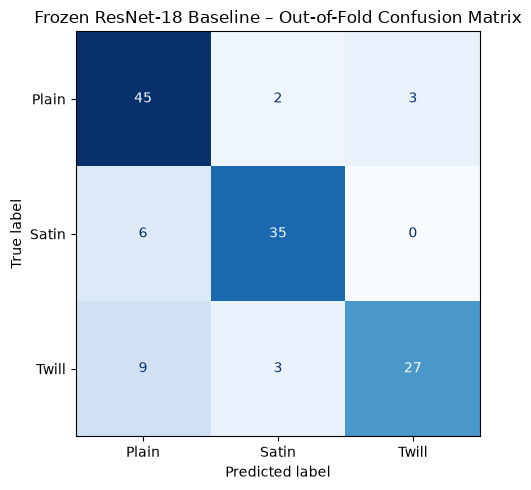

Metrics saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\frozen_baseline_metrics.csv
Confusion matrix saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\frozen_baseline_confusion_matrix.csv
Confusion figure saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\figures\frozen_baseline_confusion_matrix.png


In [19]:
y_true = baseline_predictions_df["actual_class"]
y_pred = baseline_predictions_df["predicted_class"]

accuracy = accuracy_score(y_true, y_pred)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=CLASS_NAMES, average="macro", zero_division=0
)
weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=CLASS_NAMES, average="weighted", zero_division=0
)

baseline_metrics = pd.DataFrame([{
    "method": "Frozen ResNet-18 baseline",
    "accuracy": accuracy,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "weighted_precision": weighted_precision,
    "weighted_recall": weighted_recall,
    "weighted_f1": weighted_f1
}])

print("--- Frozen baseline overall metrics ---")
display(baseline_metrics.round(4))

print("\n--- Per-class classification report ---")
print(classification_report(
    y_true,
    y_pred,
    labels=CLASS_NAMES,
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=4
))

baseline_metrics_path = OUTPUT_DIR / "frozen_baseline_metrics.csv"
baseline_metrics.to_csv(baseline_metrics_path, index=False)

# Save and display the baseline confusion matrix.
cm = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES)
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual {name}" for name in CLASS_NAMES],
    columns=[f"Predicted {name}" for name in CLASS_NAMES]
)
cm_path = OUTPUT_DIR / "frozen_baseline_confusion_matrix.csv"
cm_df.to_csv(cm_path)
display(cm_df)

fig, ax = plt.subplots(figsize=(6, 5))
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[name.capitalize() for name in CLASS_NAMES]
)
display_cm.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Frozen ResNet-18 Baseline – Out-of-Fold Confusion Matrix")
plt.tight_layout()
confusion_figure_path = FIGURES_DIR / "frozen_baseline_confusion_matrix.png"
plt.savefig(confusion_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Metrics saved:", baseline_metrics_path)
print("Confusion matrix saved:", cm_path)
print("Confusion figure saved:", confusion_figure_path)

Compare the baseline with the existing full-fine-tuned model

--- Baseline vs full fine-tuning ---


,method,accuracy,macro_precision,macro_recall,macro_f1
0,Frozen ResNet-18 baseline,0.8231,0.8417,0.8153,0.8217
1,Full fine-tuned ResNet-18,0.7846,0.8005,0.7866,0.7904
2,Difference (full fine-tuning - baseline),-0.0385,-0.0412,-0.0287,-0.0313


Comparison saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\baseline_vs_full_finetuning_comparison.csv
Paired predictions saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\baseline_vs_full_finetuning_paired_predictions.csv


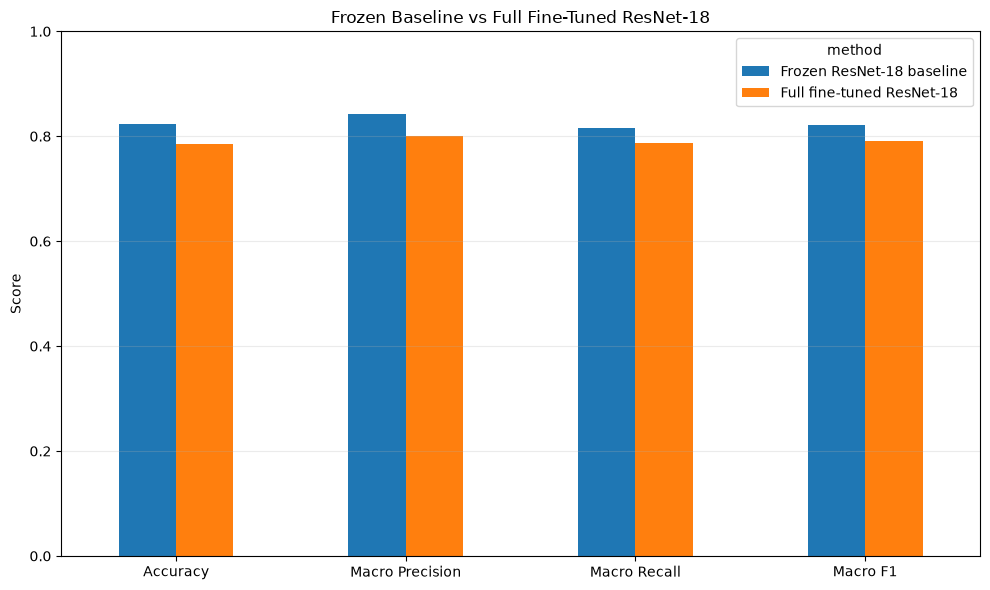

Comparison figure saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\figures\baseline_vs_full_finetuning_comparison.png


In [20]:
# Normalize labels and column types for a safe one-to-one merge.
improved_compare = improved_df.copy()
improved_compare["actual_class"] = improved_compare["actual_class"].str.lower()
improved_compare["predicted_class"] = improved_compare["predicted_class"].str.lower()

baseline_compare = baseline_predictions_df.copy()
baseline_compare["actual_class"] = baseline_compare["actual_class"].str.lower()
baseline_compare["predicted_class"] = baseline_compare["predicted_class"].str.lower()

assert set(improved_compare["image_filename"]) == set(baseline_compare["image_filename"])

paired_predictions = baseline_compare.merge(
    improved_compare[
        ["image_filename", "predicted_class", "confidence", "correct"]
    ].rename(columns={
        "predicted_class": "finetuned_predicted_class",
        "confidence": "finetuned_confidence",
        "correct": "finetuned_correct"
    }),
    on="image_filename",
    how="inner",
    validate="one_to_one"
)

assert len(paired_predictions) == 130
assert (paired_predictions["actual_class"] == paired_predictions["actual_class"]).all()


def calculate_metrics(df, prediction_column):
    actual = df["actual_class"]
    predicted = df[prediction_column]
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual, predicted, labels=CLASS_NAMES,
        average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(actual, predicted),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1
    }

baseline_comparison_metrics = calculate_metrics(
    paired_predictions, "predicted_class"
)
finetuned_comparison_metrics = calculate_metrics(
    paired_predictions, "finetuned_predicted_class"
)

comparison_df = pd.DataFrame([
    {"method": "Frozen ResNet-18 baseline", **baseline_comparison_metrics},
    {"method": "Full fine-tuned ResNet-18", **finetuned_comparison_metrics}
])

# Absolute difference: full fine-tuning minus frozen baseline.
metric_columns = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
difference_row = {"method": "Difference (full fine-tuning - baseline)"}
for column in metric_columns:
    difference_row[column] = (
        finetuned_comparison_metrics[column]
        - baseline_comparison_metrics[column]
    )
comparison_df = pd.concat(
    [comparison_df, pd.DataFrame([difference_row])],
    ignore_index=True
)

print("--- Baseline vs full fine-tuning ---")
display(comparison_df.round(4))

comparison_path = OUTPUT_DIR / "baseline_vs_full_finetuning_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)
paired_path = OUTPUT_DIR / "baseline_vs_full_finetuning_paired_predictions.csv"
paired_predictions.to_csv(paired_path, index=False)

print("Comparison saved:", comparison_path)
print("Paired predictions saved:", paired_path)

# A simple descriptive plot of the four metrics.
plot_df = comparison_df.iloc[:2].set_index("method")[metric_columns].T
ax = plot_df.plot(kind="bar", figsize=(10, 6))
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("Frozen Baseline vs Full Fine-Tuned ResNet-18")
ax.set_xticklabels(["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"], rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
comparison_figure_path = FIGURES_DIR / "baseline_vs_full_finetuning_comparison.png"
plt.savefig(comparison_figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("Comparison figure saved:", comparison_figure_path)

Fold-wise comparison

In [21]:
# Calculate fold accuracy for both model configurations.
fold_rows = []
for fold_number in range(1, 6):
    baseline_fold = baseline_compare[baseline_compare["fold"] == fold_number]
    improved_fold = improved_compare[improved_compare["fold"] == fold_number]

    fold_rows.append({
        "fold": fold_number,
        "test_images": len(baseline_fold),
        "baseline_accuracy": accuracy_score(
            baseline_fold["actual_class"], baseline_fold["predicted_class"]
        ),
        "full_finetuning_accuracy": accuracy_score(
            improved_fold["actual_class"], improved_fold["predicted_class"]
        )
    })

fold_comparison_df = pd.DataFrame(fold_rows)
fold_comparison_df["accuracy_difference"] = (
    fold_comparison_df["full_finetuning_accuracy"]
    - fold_comparison_df["baseline_accuracy"]
)

display(fold_comparison_df.round(4))
fold_comparison_path = OUTPUT_DIR / "fold_wise_accuracy_comparison.csv"
fold_comparison_df.to_csv(fold_comparison_path, index=False)
print("Fold-wise comparison saved:", fold_comparison_path)

,fold,test_images,baseline_accuracy,full_finetuning_accuracy,accuracy_difference
0,1,27,0.9630,0.5926,-0.3704
1,2,23,0.7826,0.8696,0.0870
2,3,30,0.9667,0.7667,-0.2000
3,4,26,0.7692,0.9615,0.1923
4,5,24,0.5833,0.7500,0.1667


Fold-wise comparison saved: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\fold_wise_accuracy_comparison.csv


Final output verification

In [22]:
expected_files = [
    OUTPUT_DIR / "frozen_baseline_oof_predictions.csv",
    OUTPUT_DIR / "frozen_baseline_metrics.csv",
    OUTPUT_DIR / "frozen_baseline_confusion_matrix.csv",
    OUTPUT_DIR / "baseline_vs_full_finetuning_comparison.csv",
    OUTPUT_DIR / "baseline_vs_full_finetuning_paired_predictions.csv",
    OUTPUT_DIR / "fold_wise_accuracy_comparison.csv",
    FIGURES_DIR / "frozen_baseline_confusion_matrix.png",
    FIGURES_DIR / "baseline_vs_full_finetuning_comparison.png"
]

print("--- Notebook 09 output verification ---")
missing = []
for path in expected_files:
    exists = path.exists()
    print(f"{'FOUND' if exists else 'MISSING'}: {path}")
    if not exists:
        missing.append(path)

checkpoint_files = [
    MODEL_OUTPUT_DIR / f"resnet18_frozen_baseline_fold{fold}.pth"
    for fold in range(1, 6)
]
for path in checkpoint_files:
    exists = path.exists()
    print(f"{'FOUND' if exists else 'MISSING'}: {path}")
    if not exists:
        missing.append(path)

if not missing:
    print("\nSUCCESS: All baseline outputs and checkpoints are present.")
else:
    print(f"\n{len(missing)} expected files are missing. Complete the relevant cells.")

--- Notebook 09 output verification ---
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\frozen_baseline_oof_predictions.csv
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\frozen_baseline_metrics.csv
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\frozen_baseline_confusion_matrix.csv
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\baseline_vs_full_finetuning_comparison.csv
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\baseline_comparison\baseline_vs_full_finetuning_paired_predictions.csv
FOUND: D:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-p